Part a

In [1]:
import os
import cv2
import dlib
import numpy as np
import pandas as pd
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

DATASET_PATH = r'C:\Users\TamirLand\Downloads\utkface_aligned_cropped\crop_part1'

def load_and_downsize_dataset(path, sample_size=500):
    data = []
    labels = []
    files = os.listdir(path)
    np.random.shuffle(files)  # Shuffling to ensure randomness
    for file in files[:sample_size]:
        try:
            age = int(file.split("_")[0])
        except:
            continue
        img_path = os.path.join(path, file)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # Converting to grayscale
        img = cv2.resize(img, (128, 128))  # Resizing image
        
        data.append(img)
        labels.append(age)
    return np.array(data), np.array(labels)

images, ages = load_and_downsize_dataset(DATASET_PATH)

C:\Program Files\Anaconda\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.25.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Part b

In [2]:
predictor_path = r"F:/Python library code/shape_predictor_68_face_landmarks.dat"
if not os.path.exists(predictor_path):
    raise FileNotFoundError(f"The file {predictor_path} does not exist.")
face_detector = dlib.get_frontal_face_detector()
landmark_predictor = dlib.shape_predictor(predictor_path)

def extract_landmarks(images):
    features = []
    for img in images:
        detections = face_detector(img)
        if len(detections) > 0:
            shape = landmark_predictor(img, detections[0])
            landmarks = []
            for i in range(68):
                landmarks.append(shape.part(i).x)
                landmarks.append(shape.part(i).y)
            features.append(landmarks)
        else:
            features.append([0] * 136)  # Placeholdering for missing faces
    return np.array(features)

landmarks = extract_landmarks(images)

Part c

In [3]:
def calculate_features(landmarks):
    features = []
    for lm in landmarks:
        eye_distance = np.linalg.norm([lm[36*2] - lm[45*2], lm[36*2+1] - lm[45*2+1]])
        nose_width = np.linalg.norm([lm[31*2] - lm[35*2], lm[31*2+1] - lm[35*2+1]])
        mouth_width = np.linalg.norm([lm[48*2] - lm[54*2], lm[48*2+1] - lm[54*2+1]])
        jaw_width = np.linalg.norm([lm[0*2] - lm[16*2], lm[0*2+1] - lm[16*2+1]])
        features.append([eye_distance, nose_width, mouth_width, jaw_width])
    return np.array(features)

features = calculate_features(landmarks)

Part d

In [4]:
output_df = pd.DataFrame(features, columns=['Eye_Distance', 'Nose_Width', 'Mouth_Width', 'Jaw_Width'])
output_df['Age'] = ages
output_df.to_csv('features_with_labels.csv', index=False)

Part e

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(features)
Y = ages

Part f

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=pd.cut(Y, 10))

Part g

In [7]:
svr_linear = SVR(kernel='linear', C=1.0, epsilon=0.2)
svr_linear.fit(X_train, y_train)
y_pred_linear = svr_linear.predict(X_test)
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
print(f'MAE (Linear Kernel): {mae_linear}')
print(f'RMSE (Linear Kernel): {rmse_linear}')

MAE (Linear Kernel): 16.524008088072648
RMSE (Linear Kernel): 22.553856374434478


Part h

In [8]:
for degree in [2, 3, 4]:
    svr_poly = SVR(kernel='poly', degree=degree, C=1.0, epsilon=0.2)
    svr_poly.fit(X_train, y_train)
    y_pred_poly = svr_poly.predict(X_test)
    print(f'Polynomial Kernel (degree={degree}): MAE={mean_absolute_error(y_test, y_pred_poly)}, RMSE={np.sqrt(mean_squared_error(y_test, y_pred_poly))}')

for gamma in [0.1, 0.5, 1.0]:
    svr_rbf = SVR(kernel='rbf', C=1.0, gamma=gamma, epsilon=0.2)
    svr_rbf.fit(X_train, y_train)
    y_pred_rbf = svr_rbf.predict(X_test)
    print(f'RBF Kernel (gamma={gamma}): MAE={mean_absolute_error(y_test, y_pred_rbf)}, RMSE={np.sqrt(mean_squared_error(y_test, y_pred_rbf))}')

Polynomial Kernel (degree=2): MAE=18.090659311423117, RMSE=22.71806243153586
Polynomial Kernel (degree=3): MAE=17.724426259798772, RMSE=21.860303527414928
Polynomial Kernel (degree=4): MAE=18.571329410881347, RMSE=23.00104516012295
RBF Kernel (gamma=0.1): MAE=15.49915419253366, RMSE=19.490207774730255
RBF Kernel (gamma=0.5): MAE=14.550791432841974, RMSE=18.59217227414945
RBF Kernel (gamma=1.0): MAE=14.832310484807106, RMSE=19.098911312402244


Part i, j, l and m

Gaussian Noise (sigma=0): MAE=15.140261341298991, RMSE=19.03381759613063


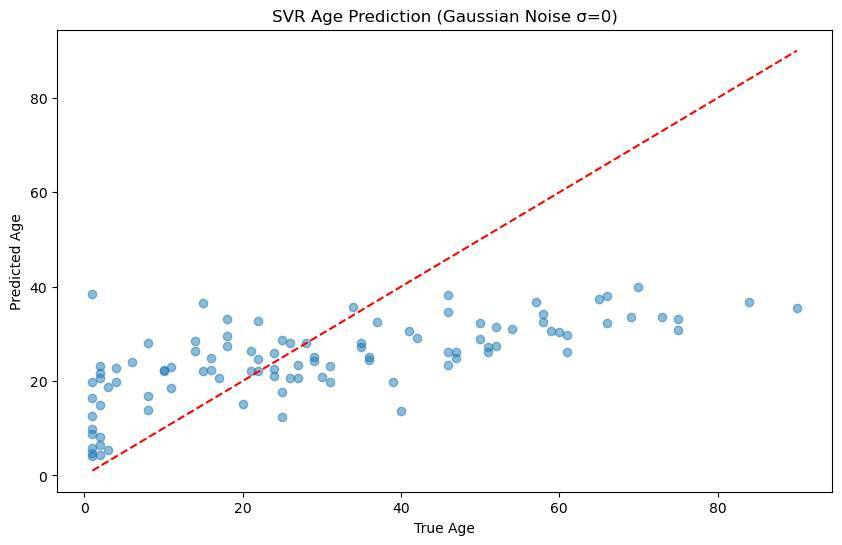

Gaussian Noise (sigma=0.5): MAE=16.329640745684063, RMSE=19.990843840718988


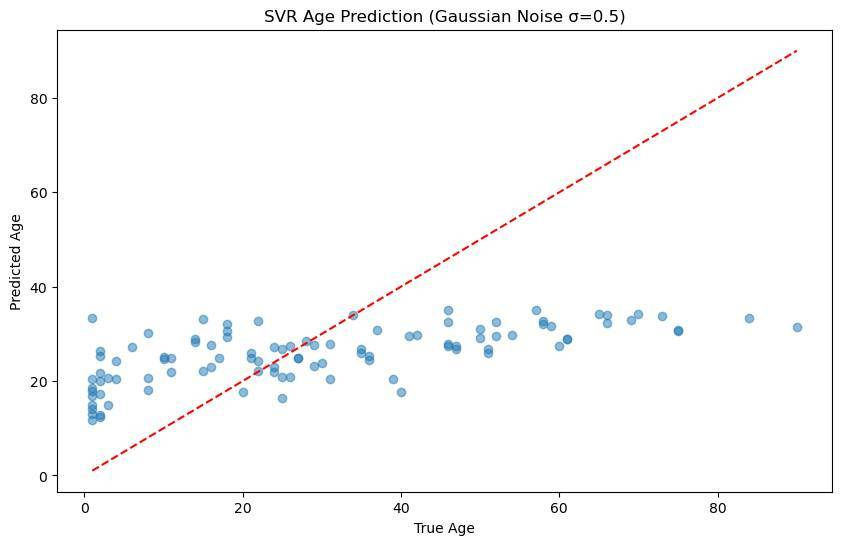

Gaussian Noise (sigma=1): MAE=17.52890373265568, RMSE=21.61374107877321


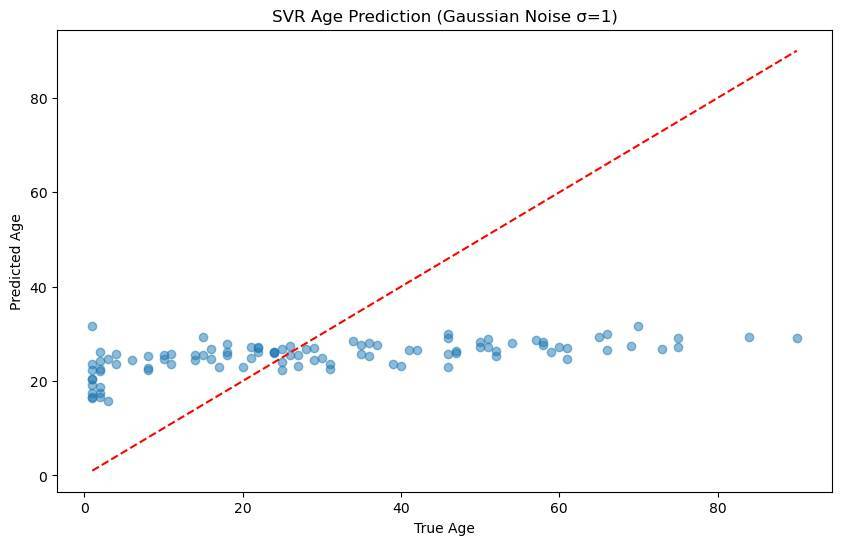

Gaussian Noise (sigma=2): MAE=18.077034239854854, RMSE=22.096795956248375


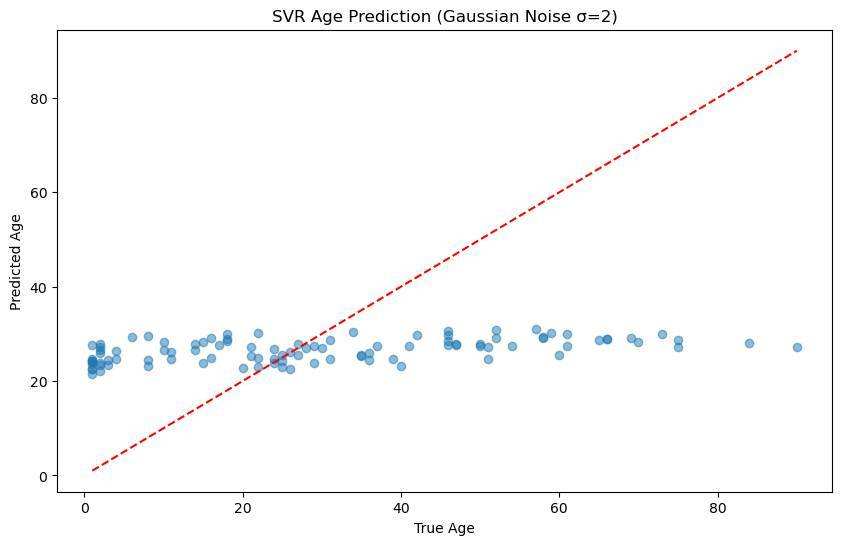

In [9]:
for sigma in [0, 0.5, 1, 2]:
    noisy_X = X + np.random.normal(0, sigma, X.shape)
    svr_noisy = SVR(kernel='rbf', C=1.0, gamma=0.1, epsilon=0.2)
    svr_noisy.fit(noisy_X, Y)
    y_pred_noisy = svr_noisy.predict(X_test)
    print(f'Gaussian Noise (sigma={sigma}): MAE={mean_absolute_error(y_test, y_pred_noisy)}, RMSE={np.sqrt(mean_squared_error(y_test, y_pred_noisy))}')
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred_noisy, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '--r')
    plt.xlabel("True Age")
    plt.ylabel("Predicted Age")
    plt.title(f'SVR Age Prediction (Gaussian Noise σ={sigma})')
    plt.show()